<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/Restnet50-new/notebook/resnet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import sys
import json
import hashlib
import time
import random
import platform
import shutil
import subprocess
import gc

import numpy as np
import pandas as pd
import tensorflow as tf
import keras
import sklearn
import kagglehub
import matplotlib
import matplotlib.pyplot as plt

# Architecture-specific preprocessor for ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocess_input

print("All imports completed successfully.")

All imports completed successfully.


In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
    determinism_status = "TensorFlow op determinism enabled"
except Exception as e:
    determinism_status = f"Could not enable op determinism: {e}"

print(f"Seed:        {SEED}")
print(f"Determinism: {determinism_status}")

Seed:        42
Determinism: TensorFlow op determinism enabled


In [4]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        gpu_name = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
        nvidia_smi = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            text=True,
        ).strip().splitlines()[0]
    except Exception:
        gpu_name = tf.config.experimental.get_device_details(gpus[0]).get('device_name', 'Unknown GPU')
        nvidia_smi = 'Unavailable'
else:
    gpu_name = 'No GPU detected'
    nvidia_smi = 'N/A'

environment_info = {
    'member': 3,
    'model': 'ResNet50',
    'python_version': sys.version,
    'platform': platform.platform(),
    'tensorflow_version': tf.__version__,
    'keras_version': keras.__version__,
    'numpy_version': np.__version__,
    'pandas_version': pd.__version__,
    'scikit_learn_version': sklearn.__version__,
    'kagglehub_version': getattr(kagglehub, '__version__', 'unknown'),
    'matplotlib_version': matplotlib.__version__,
    'gpu_name': gpu_name,
    'nvidia_smi': nvidia_smi,
    'seed': SEED,
    'determinism_status': determinism_status,
}

print('Environment Recorded:')
for k, v in environment_info.items():
    print(f'  {k:<22}: {v}')

Environment Recorded:
  member                : 3
  model                 : ResNet50
  python_version        : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
  platform              : Linux-6.6.122+-x86_64-with-glibc2.39
  tensorflow_version    : 2.21.0
  keras_version         : 3.13.2
  numpy_version         : 2.1.3
  pandas_version        : 2.2.3
  scikit_learn_version  : 1.6.1
  kagglehub_version     : 1.0.2
  matplotlib_version    : 3.10.0
  gpu_name              : Tesla T4
  nvidia_smi            : Tesla T4, 580.82.07, 15360 MiB
  seed                  : 42
  determinism_status    : TensorFlow op determinism enabled


In [5]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
from pathlib import Path

# Folder layout expected inside Dataset:
#   Dataset/ga/correct, Dataset/ga/wrong, Dataset/ra/correct, ... (5 letters x correct/wrong)
PROJECT_DIR = Path("/content/drive/MyDrive/dataset")
DATA_DIR = Path("/content/drive/MyDrive/dataset")
SPLITS_DIR = PROJECT_DIR / "data" / "splits_10class"
RESULTS_DIR = PROJECT_DIR / "results_10class"
PLOTS_DIR = RESULTS_DIR / "plots"
METRICS_DIR = RESULTS_DIR / "metrics"
MODELS_DIR = PROJECT_DIR / "models_10class"
FINAL_MODEL_DIR = MODELS_DIR / "final"
CHECKPOINT_DIR = MODELS_DIR / "checkpoints"

for folder in [
    SPLITS_DIR, PLOTS_DIR, METRICS_DIR, FINAL_MODEL_DIR, CHECKPOINT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Scan the dataset (`correct` / `wrong`)

Expected layout (inside `DATA_DIR`):
```
raw/
  correct/  img1.jpg, img2.png, ...
  wrong/    img1.jpg, ...
```
This cell lists every image, checks that it opens, removes exact duplicates (so the same image can't end up in both train and test), and builds a table of `path / label / class`.

In [7]:
import io
from PIL import Image

# Image settings
IMG_HEIGHT = 224          # ResNet50 standard input size
IMG_WIDTH  = 224
BATCH_SIZE = 32

LETTERS = ["ga", "ra", "ta", "u", "la"]          # folder names of the 5 letters
STATES  = ["correct", "wrong"]                   # sub-folder names inside each letter
CLASS_NAMES = [f"{l}_{s}" for l in LETTERS for s in STATES]   # 10 classes -> labels 0..9
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_EXTS  = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(f"DATA_DIR not found: {DATA_DIR}  -> check the path in the paths cell")

rows, corrupt = [], []
for letter in LETTERS:
    for state in STATES:
        cls = f"{letter}_{state}"
        cls_dir = DATA_DIR / letter / state
        if not cls_dir.is_dir():
            raise FileNotFoundError(
                f"Missing folder: {cls_dir}\nFolders found in DATA_DIR: {[p.name for p in DATA_DIR.iterdir()]}"
            )
        for p in sorted(cls_dir.rglob("*")):
            if p.suffix.lower() not in IMAGE_EXTS:
                continue
            try:
                data = p.read_bytes()
                Image.open(io.BytesIO(data)).verify()          # raises if the file is broken
                rows.append({"path": str(p), "label": CLASS_TO_ID[cls], "class": cls,
                             "letter": letter, "state": state,
                             "md5": hashlib.md5(data).hexdigest()})
            except Exception as e:
                corrupt.append((str(p), str(e)))

df = pd.DataFrame(rows)
print(f"Valid images found : {len(df)}")
print(f"Corrupt/unreadable : {len(corrupt)}")
for path, err in corrupt[:5]:
    print("   ", path, "->", err)

# Same image present in DIFFERENT folders = conflicting label -> remove all copies
n_labels_per_hash = df.groupby("md5")["label"].nunique()
conflict_hashes = n_labels_per_hash[n_labels_per_hash > 1].index
if len(conflict_hashes):
    print(f"WARNING: {len(conflict_hashes)} image(s) appear in more than one folder -> removed")
    df = df[~df["md5"].isin(conflict_hashes)]

# Exact duplicates inside the same class -> keep one copy
n_before = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Exact duplicates removed: {n_before - len(df)}")

print("\nImages per class:")
print(df["class"].value_counts().reindex(CLASS_NAMES).to_string())

Valid images found : 1001
Corrupt/unreadable : 0
Exact duplicates removed: 2

Images per class:
class
ga_correct    113
ga_wrong       88
ra_correct    125
ra_wrong       74
ta_correct     79
ta_wrong      121
u_correct      65
u_wrong       135
la_correct     63
la_wrong      136


## 2. Train / validation / test split (70 / 15 / 15, stratified)

The split is saved as CSV files so every experiment (and every team member) uses exactly the same images.

In [8]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part.to_csv(SPLITS_DIR / f"{name}.csv", index=False)
    counts = part["class"].value_counts().to_dict()
    print(f"{name:<5}: {len(part):>5} images  {counts}")

train:   699 images  {'la_wrong': 95, 'u_wrong': 94, 'ra_correct': 87, 'ta_wrong': 85, 'ga_correct': 79, 'ga_wrong': 62, 'ta_correct': 55, 'ra_wrong': 52, 'u_correct': 46, 'la_correct': 44}
val  :   150 images  {'la_wrong': 21, 'u_wrong': 21, 'ra_correct': 19, 'ta_wrong': 18, 'ga_correct': 17, 'ga_wrong': 13, 'ta_correct': 12, 'ra_wrong': 11, 'u_correct': 9, 'la_correct': 9}
test :   150 images  {'u_wrong': 20, 'la_wrong': 20, 'ra_correct': 19, 'ta_wrong': 18, 'ga_correct': 17, 'ga_wrong': 13, 'ta_correct': 12, 'ra_wrong': 11, 'u_correct': 10, 'la_correct': 10}


## 3. Preprocessing: same size + pure black & white

Steps for every image:
1. Decode (works for JPG / PNG / BMP)
2. Convert to grayscale
3. Pick a threshold (Otsu = automatic per image, or a fixed value)
4. Resize to 224x224 **keeping the aspect ratio** (the letter shape is not stretched; padding is white)
5. Threshold into pure black (0) and white (255)
6. Copy the 1 channel into 3 channels and apply ResNet50 `preprocess_input`

The black/white result is cached in memory (uint8, 1 channel) so only the first epoch reads from Drive.

In [9]:
USE_OTSU        = True     # True: automatic threshold per image | False: use FIXED_THRESHOLD
FIXED_THRESHOLD = 127.0

def otsu_threshold(gray):
    """gray: float32 tensor with values 0-255. Returns Otsu's threshold as a scalar."""
    hist  = tf.cast(tf.histogram_fixed_width(gray, [0.0, 256.0], nbins=256), tf.float32)
    bins  = tf.range(256, dtype=tf.float32)
    w_bg  = tf.cumsum(hist)                         # pixels at or below each level
    w_fg  = tf.reduce_sum(hist) - w_bg              # pixels above each level
    s_all = tf.reduce_sum(hist * bins)
    s_bg  = tf.cumsum(hist * bins)
    m_bg  = s_bg / tf.maximum(w_bg, 1.0)
    m_fg  = (s_all - s_bg) / tf.maximum(w_fg, 1.0)
    between_class_variance = w_bg * w_fg * tf.square(m_bg - m_fg)
    return tf.cast(tf.argmax(between_class_variance), tf.float32)

def load_and_binarize(file_path):
    """Image path -> uint8 tensor [224, 224, 1] containing only 0 (black) and 255 (white)."""
    img = tf.io.decode_image(tf.io.read_file(file_path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])

    gray = tf.image.rgb_to_grayscale(tf.cast(img, tf.float32))        # [H, W, 1], 0-255
    thr  = otsu_threshold(gray) if USE_OTSU else FIXED_THRESHOLD       # threshold from the original image

    # Resize with aspect ratio kept. resize_with_pad pads with 0, so invert -> resize -> invert back
    # to make the padding white instead of black.
    inverted = 255.0 - gray
    inverted = tf.image.resize_with_pad(inverted, IMG_HEIGHT, IMG_WIDTH, antialias=True)
    gray     = 255.0 - inverted

    bw = tf.where(gray > thr, 255.0, 0.0)                              # pure black & white
    return tf.cast(bw, tf.uint8)

def to_resnet_input(bw, label):
    """[224, 224, 1] uint8 B&W -> [224, 224, 3] float32 in ResNet50's expected input format."""
    x = tf.tile(tf.cast(bw, tf.float32), [1, 1, 3])
    return resnet50_preprocess_input(x), label

def make_dataset(df_part, training):
    paths  = df_part["path"].tolist()
    labels = df_part["label"].astype("int32").tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(lambda p, y: (load_and_binarize(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()                                   # keep the small B&W images in RAM after epoch 1
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(to_resnet_input, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

## 4. Visual check

Look at a few results before training. Letters should be clearly black on white, not broken or filled in. If they look wrong, try `USE_OTSU = False` and change `FIXED_THRESHOLD`.

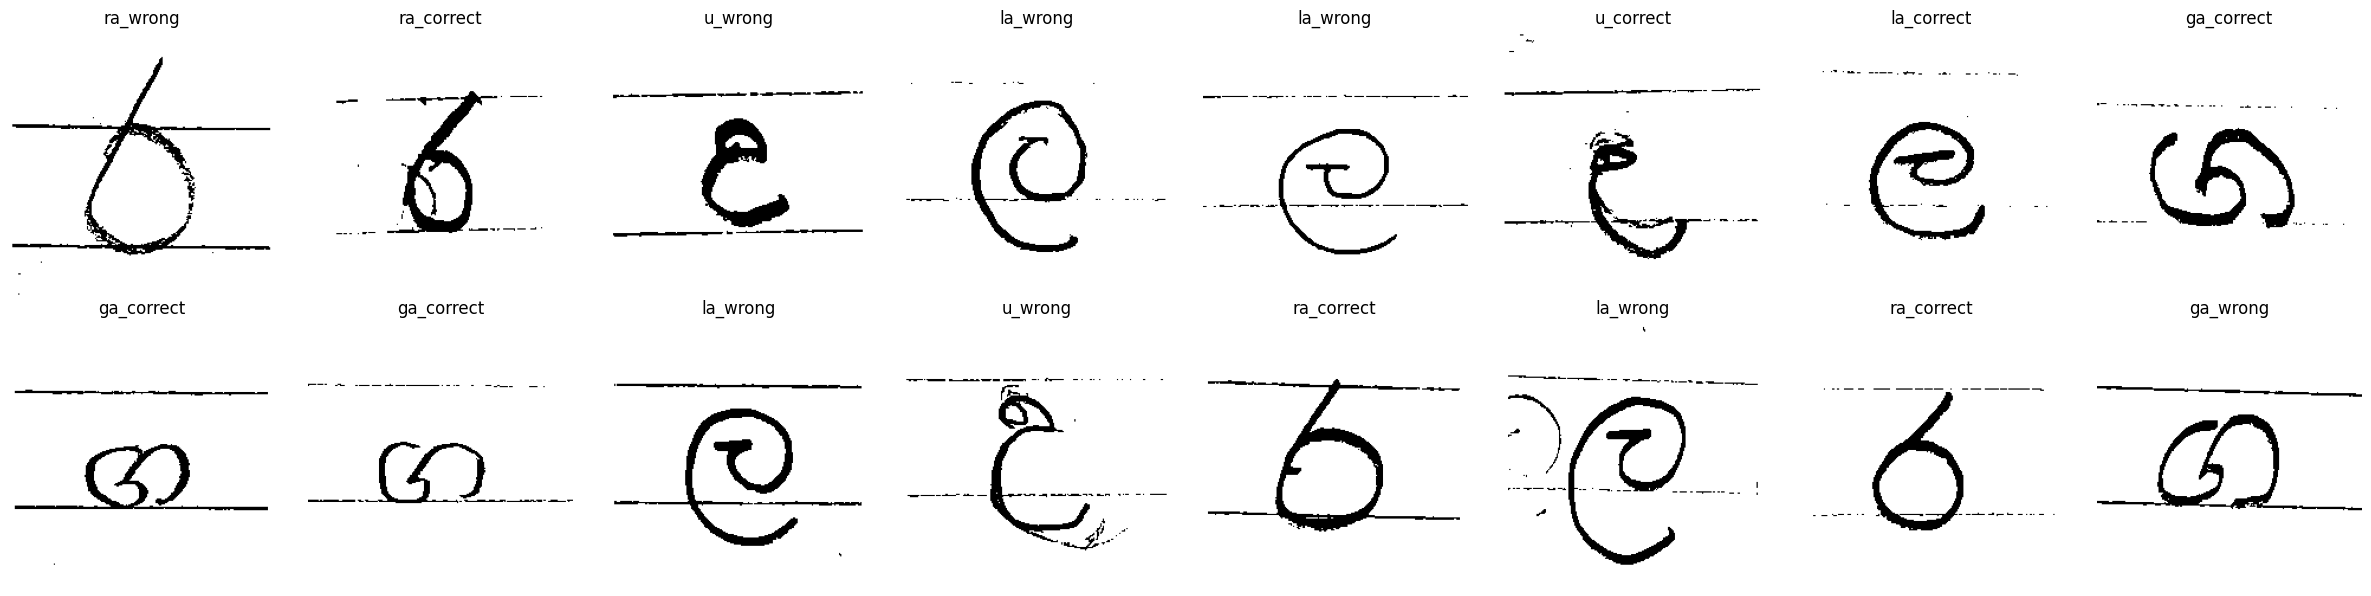

In [10]:
def show_samples(df_part, n=16):
    n = min(n, len(df_part))
    sample = df_part.sample(n, random_state=SEED)
    cols = max(n // 2, 1)
    fig, axes = plt.subplots(2, cols, figsize=(3 * cols, 6))
    for ax, (_, r) in zip(np.ravel(axes), sample.iterrows()):
        bw = load_and_binarize(r["path"]).numpy().squeeze()
        ax.imshow(bw, cmap="gray", vmin=0, vmax=255)
        ax.set_title(r["class"])
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_df)

## 5. Build the datasets

In [11]:
train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

# Sanity check on one batch
x, y = next(iter(train_ds))
print("Batch images :", x.shape, x.dtype)
print("Batch labels :", y.shape, y.dtype)
print(f"Value range  : {float(tf.reduce_min(x)):.1f} to {float(tf.reduce_max(x)):.1f}")

# Class weights (helps if one class has far fewer images)
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weight = {i: float(w[i]) for i in range(NUM_CLASSES)}
print("Class weights:", class_weight, "| labels:", dict(enumerate(CLASS_NAMES)))

Batch images : (32, 224, 224, 3) <dtype: 'float32'>
Batch labels : (32,) <dtype: 'int32'>
Value range  : -123.7 to 151.1
Class weights: {0: 0.8848101265822785, 1: 1.1274193548387097, 2: 0.803448275862069, 3: 1.3442307692307693, 4: 1.270909090909091, 5: 0.8223529411764706, 6: 1.5195652173913043, 7: 0.7436170212765958, 8: 1.5886363636363636, 9: 0.7357894736842105} | labels: {0: 'ga_correct', 1: 'ga_wrong', 2: 'ra_correct', 3: 'ra_wrong', 4: 'ta_correct', 5: 'ta_wrong', 6: 'u_correct', 7: 'u_wrong', 8: 'la_correct', 9: 'la_wrong'}


## 6. Build the ResNet50 model

Paste these cells **below your last cell** (they use `train_ds`, `val_ds`, `class_weight`, `CLASS_NAMES`, `CHECKPOINT_DIR`, `FINAL_MODEL_DIR`, `METRICS_DIR`, `PLOTS_DIR` from the earlier cells).

Before running: Runtime → Change runtime type → **T4 GPU**.

Plan (standard transfer learning):
1. **Stage 1:** ResNet50 pretrained on ImageNet is frozen, only the new classifier head is trained.
2. **Stage 2:** the last layers of ResNet50 are unfrozen and fine-tuned with a very small learning rate.

The model outputs one number: the probability of **class 1** (`CLASS_NAMES[1]`, which is `Wrong`). Precision and recall below are therefore for the `Wrong` class.

In [12]:
from tensorflow.keras import layers, models, optimizers, callbacks, metrics

gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "NONE - switch the runtime to a T4 GPU, training on CPU is extremely slow")

# ---------------- Model / training settings ----------------
WEIGHTS          = "imagenet"   # pretrained weights
DROPOUT          = 0.5
USE_AUGMENTATION = True         # light shift/zoom only (no flips, no rotation: they can change a letter's meaning)

EPOCHS_HEAD      = 15           # stage 1 (early stopping may end it sooner)
EPOCHS_FINE      = 30           # stage 2 (early stopping may end it sooner)
LR_HEAD          = 1e-3
LR_FINE          = 1e-5
UNFREEZE_LAST_N  = 20           # how many of ResNet50's last layers to fine-tune in stage 2

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [13]:
def build_resnet50(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), dropout=DROPOUT, augment=USE_AUGMENTATION):
    # include_top=False removes the 1000-class ImageNet classifier, we add our own head
    base = tf.keras.applications.ResNet50(
        include_top=False, weights=WEIGHTS, input_shape=input_shape)
    base.trainable = False                       # stage 1: backbone frozen

    inputs = layers.Input(shape=input_shape, name="image")   # already ResNet50-preprocessed by the data pipeline
    x = inputs
    if augment:
        x = layers.RandomTranslation(0.05, 0.05, fill_mode="nearest")(x)
        x = layers.RandomZoom(0.05, fill_mode="nearest")(x)

    x = base(x, training=False)                  # keeps BatchNorm in inference mode (important for fine-tuning)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probs")(x)

    model = models.Model(inputs, outputs, name="resnet50_letter_10class")
    return model, base


def compile_model(model, lr):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",   # labels are integers 0..9
        metrics=["accuracy"],
    )


def make_callbacks(stage):
    return [
        callbacks.ModelCheckpoint(
            str(CHECKPOINT_DIR / f"resnet50_{stage}_best.keras"),
            monitor="val_loss", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]


def count_params(model):
    trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    total = int(model.count_params())
    return trainable, total


model, base = build_resnet50()
compile_model(model, LR_HEAD)

trainable, total = count_params(model)
print(f"Stage 1 | trainable params: {trainable:,} of {total:,}")
print("Output classes:", dict(enumerate(CLASS_NAMES)))
model.summary(show_trainable=True)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Stage 1 | trainable params: 20,490 of 23,608,202
Output classes: {0: 'ga_correct', 1: 'ga_wrong', 2: 'ra_correct', 3: 'ra_wrong', 4: 'ta_correct', 5: 'ta_wrong', 6: 'u_correct', 7: 'u_wrong', 8: 'la_correct', 9: 'la_wrong'}


Model: "resnet50_letter_10class"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ random_translation          │ (None, 224, 224, 3)   │          0 │   -   │
│ (RandomTranslation)         │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ random_zoom (RandomZoom)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ class_probs (Dense)         │ (None, 10)            │     20,490 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 7. Stage 1 - train the classifier head (ResNet50 frozen)

In [14]:
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight,
    callbacks=make_callbacks("head"),
)

Epoch 1/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.1600 - loss: 2.7659
Epoch 1: val_loss improved from None to 1.71989, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 19s 418ms/step - accuracy: 0.1688 - loss: 2.6760 - val_accuracy: 0.4400 - val_loss: 1.7199 - learning_rate: 0.0010
Epoch 2/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.3005 - loss: 2.1024
Epoch 2: val_loss did not improve from 1.71989
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 169ms/step - accuracy: 0.3362 - loss: 1.9930 - val_accuracy: 0.3467 - val_loss: 1.7510 - learning_rate: 0.0010
Epoch 3/15
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.3336 - loss: 1.7748
Epoch 3: val_loss improved from 1.71989 to 1.34582, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_head_best.k

## 8. Stage 2 - fine-tune the last ResNet50 layers

Only the last `UNFREEZE_LAST_N` layers are unfrozen. BatchNorm layers stay frozen, and the learning rate is 100x smaller so the pretrained features are adjusted gently instead of destroyed.

In [15]:
base.trainable = True
for layer in base.layers[:-UNFREEZE_LAST_N]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, LR_FINE)          # must re-compile after changing trainable flags

trainable, total = count_params(model)
print(f"Stage 2 | trainable params: {trainable:,} of {total:,}")

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    class_weight=class_weight,
    callbacks=make_callbacks("finetune"),
)

Stage 2 | trainable params: 8,939,530 of 23,608,202
Epoch 1/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.6770 - loss: 0.8360
Epoch 1: val_loss improved from None to 1.11516, saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_finetune_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/dataset/models_10class/checkpoints/resnet50_finetune_best.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 16s 385ms/step - accuracy: 0.6695 - loss: 0.8533 - val_accuracy: 0.5067 - val_loss: 1.1152 - learning_rate: 1.0000e-05
Epoch 2/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.6684 - loss: 0.7753
Epoch 2: val_loss did not improve from 1.11516
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 193ms/step - accuracy: 0.6710 - loss: 0.7561 - val_accuracy: 0.5200 - val_loss: 1.2242 - learning_rate: 1.0000e-05
Epoch 3/30
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.6779 - loss: 0.7456
Epoch 3: val_loss improved from 1.11516 to 1.01910, saving model to /content/d

## 9. Training curves + save